This notebook trains the neural policy with **simple SGA** and **Adam optimizer** using the average of **H** independent policy-gradient estimates at each update.

In [ ]:
import random
import torch
import matplotlib.pyplot as plt
import numpy as np

from policy_network import build_default_policy
from simple_SGA import simple_SGA
from adam_train import adam_train

Part (c): Using simple_SGA

Learning rates tried for this method: **0.005, 0.01, 0.02**.

Empirically found that
- `0.005`: Essentially flat (noise dominates learning)
- `0.01`: Essentially flat (noise dominates learning)
- `0.02`: Significant learning after around 750 iterations

lr=0.005, iter 0: avg_grad_norm=4.0644e-01, objective=-34.9896
lr=0.005, iter 50: avg_grad_norm=3.5176e-01, objective=-33.3892
lr=0.005, iter 100: avg_grad_norm=2.5466e-01, objective=-15.7455
lr=0.005, iter 150: avg_grad_norm=3.2528e-01, objective=-22.3398
lr=0.005, iter 200: avg_grad_norm=4.4435e-01, objective=-31.2608
lr=0.005, iter 250: avg_grad_norm=4.1896e-01, objective=-24.9177
lr=0.005, iter 300: avg_grad_norm=4.6264e-01, objective=-45.6290
lr=0.005, iter 350: avg_grad_norm=3.4268e-01, objective=-34.4276
lr=0.005, iter 400: avg_grad_norm=3.3514e-01, objective=-23.4305
lr=0.005, iter 450: avg_grad_norm=5.5334e-01, objective=-28.1905
lr=0.005, iter 500: avg_grad_norm=4.3077e-01, objective=-28.3898
lr=0.005, iter 550: avg_grad_norm=3.4239e-01, objective=-22.3630
lr=0.005, iter 600: avg_grad_norm=4.2878e-01, objective=-23.9159
lr=0.005, iter 650: avg_grad_norm=2.0916e-01, objective=-19.3995
lr=0.005, iter 700: avg_grad_norm=5.7811e-01, objective=-24.4724
lr=0.005, iter 750: avg_grad

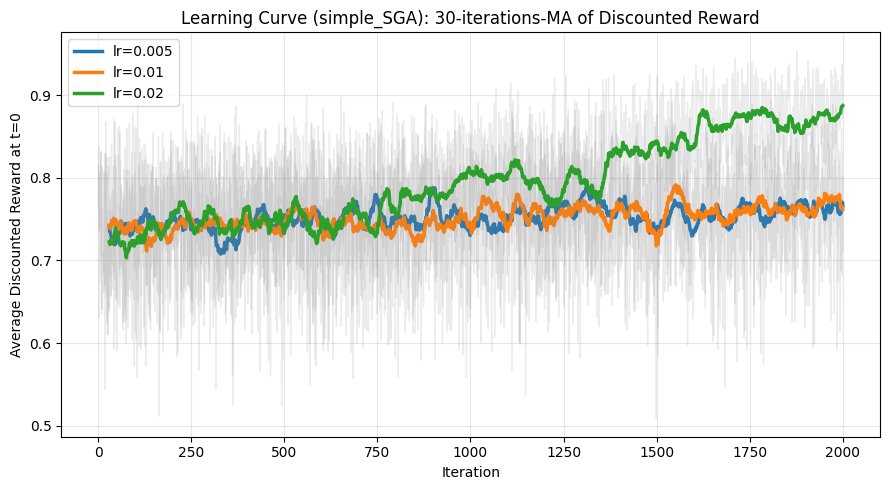

In [4]:
# Reproducibility
torch.manual_seed(42)
random.seed(42)

learning_rates = [0.005, 0.01, 0.02]
# learning_rates = [0.02]
iterations = 2000
H = 16
gamma = 0.99
max_steps = 40
eval_episodes = 25

results = {}
for lr in learning_rates:
    policy = build_default_policy(grid_size=4)
    history = simple_SGA(
        policy=policy,
        grid_size=4,
        iterations=iterations,
        H=H,
        learning_rate=lr,
        gamma=gamma,
        max_steps=max_steps,
        eval_episodes=eval_episodes,
    )
    results[lr] = history
    print(f'Completed lr={lr} | Final Discounted Reward={history["discounted_reward_curve"][-1]:.3f}')

window = 30  # moving-average window
plt.figure(figsize=(9, 5))
# color chosen for this learning rate
colors = ['C0', 'C1', 'C2']
for i, lr in enumerate(learning_rates):
    curve = np.array(results[lr]['discounted_reward_curve'])
    color = colors[i % len(colors)]
    # faded noisy curve in the background
    plt.plot(range(1, len(curve) + 1), curve, color='gray', alpha=0.15, linewidth=1)
    # moving average (main focus)
    if len(curve) >= window:
        ma = np.convolve(curve, np.ones(window)/window, mode='valid')
        x_ma = range(window, window + len(ma))
        plt.plot(x_ma, ma, label=f'lr={lr}', color=color, linewidth=2.5)
    else:
        plt.plot(range(1, len(curve) + 1), curve, label=f'lr={lr}', color=color, linewidth=2.5)

plt.xlabel('Iteration')
plt.ylabel('Average Discounted Reward at t=0')
plt.title(f'Learning Curve (simple_SGA): {window}-iterations-MA of Discounted Reward')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Part (d): Using Adam optimizer

Learning rates tried (requires to be smaller comparitively): **0.001, 0.005, 0.01**.

Empirically found that
- `0.001`: conservative and stable
- `0.005`: learns faster but bounces out of stable region after 1500 iters
- `0.01`: unstable (policy collapse), a single bad batch of trajectories produces massive inaccurate gradient

lr=0.001, iter 0: avg_grad_norm=4.0644e-01, objective=-34.9896
lr=0.001, iter 50: avg_grad_norm=4.8726e-01, objective=-23.0717
lr=0.001, iter 100: avg_grad_norm=5.4147e-01, objective=-29.8688
lr=0.001, iter 150: avg_grad_norm=5.1886e-01, objective=-29.3668
lr=0.001, iter 200: avg_grad_norm=5.5130e-01, objective=-27.8865
lr=0.001, iter 250: avg_grad_norm=4.0955e-01, objective=-23.7631
lr=0.001, iter 300: avg_grad_norm=6.3222e-01, objective=-21.7973
lr=0.001, iter 350: avg_grad_norm=8.3970e-01, objective=-21.3153
lr=0.001, iter 400: avg_grad_norm=6.1610e-01, objective=-17.6987
lr=0.001, iter 450: avg_grad_norm=9.3734e-01, objective=-23.6230
lr=0.001, iter 500: avg_grad_norm=6.3762e-01, objective=-13.4877
lr=0.001, iter 550: avg_grad_norm=1.2072e+00, objective=-20.6557
lr=0.001, iter 600: avg_grad_norm=6.6720e-01, objective=-19.8198
lr=0.001, iter 650: avg_grad_norm=1.3853e+00, objective=-23.6339
lr=0.001, iter 700: avg_grad_norm=6.9022e-01, objective=-13.1928
lr=0.001, iter 750: avg_grad

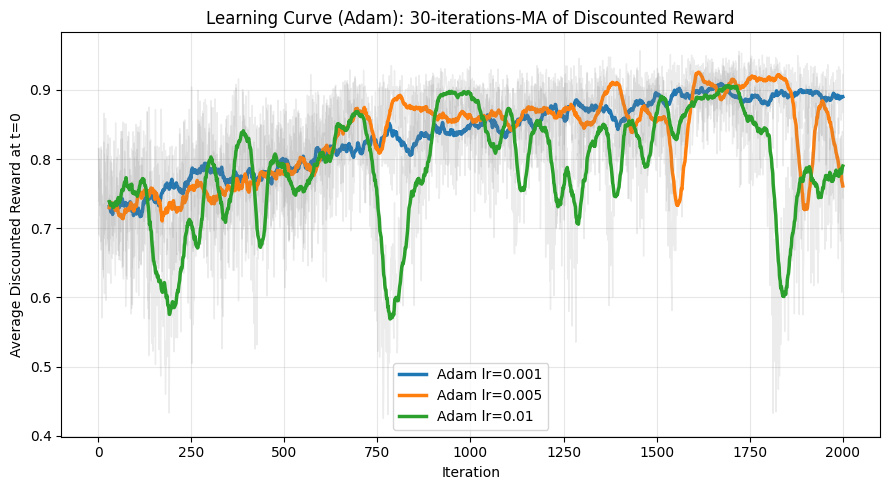

In [ ]:
# Reproducibility
torch.manual_seed(42)
random.seed(42)

learning_rates = [0.001, 0.005, 0.01] 
iterations = 2000
H = 16
gamma = 0.99
max_steps = 40
eval_episodes = 25

results = {}
for lr in learning_rates:
    policy = build_default_policy(grid_size=4)
    history = adam_train(
        policy=policy,
        grid_size=4,
        iterations=iterations,
        H=H,
        learning_rate=lr,
        gamma=gamma,
        max_steps=max_steps,
        eval_episodes=eval_episodes,
    )
    results[lr] = history
    print(f'Completed Adam lr={lr} | Final Discounted Reward={history["discounted_reward_curve"][-1]:.3f}')

window = 30  # moving-average window
plt.figure(figsize=(9, 5))

# colors chosen for the learning rates
colors = ['C0', 'C1', 'C2']
for i, lr in enumerate(learning_rates):
    curve = np.array(results[lr]['discounted_reward_curve'])
    color = colors[i % len(colors)]
    
    # faded noisy curve in the background
    plt.plot(range(1, len(curve) + 1), curve, color='gray', alpha=0.15, linewidth=1)
    
    # moving average (main focus)
    if len(curve) >= window:
        ma = np.convolve(curve, np.ones(window)/window, mode='valid')
        x_ma = range(window, window + len(ma))
        plt.plot(x_ma, ma, label=f'Adam lr={lr}', color=color, linewidth=2.5)
    else:
        plt.plot(range(1, len(curve) + 1), curve, label=f'Adam lr={lr}', color=color, linewidth=2.5)

plt.xlabel('Iteration')
plt.ylabel('Average Discounted Reward at t=0')
plt.title(f'Learning Curve (Adam): {window}-iterations-MA of Discounted Reward')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()